# MOM6 eddy exp1: exponential initialisation

This notebook regenerates only `mom6-eddy-exp1/input/initial_state.nc` from this experiment's YAML and Python generator. H = 500 m, surface peak speed 0.20 m/s, peak-speed diameter 100 km. The smooth exponential profile has no finite cutoff. No Payu job is submitted by this notebook.

## Experiment-specific configuration

Exp1 uses a 100 × 100 Cartesian grid at 5,000 m spacing, closed horizontal boundaries, 100 nonuniform vertical layers, and the copied experiment's bathymetry. Local files in `initialisation/reference/` supply geometry templates; they contain no restart state. Their geometry and ALE definition are checked against this experiment before generation.

Current Coriolis settings are read from this experiment: `F_0 = -1e-4 s⁻¹`, `BETA = 2e-11 m⁻¹ s⁻¹`, `BETA_LAT_REF = 0 m`. Thus f ranges from −1e-4 to −9e-5 s⁻¹, with centre f = −9.5e-5 s⁻¹. Coriolis is recomputed from these settings, rather than inherited from the template grid. Cyclonic rotation is clockwise.

The linear EOS and background nominal-layer temperature profile are read and checked as before. Velocity/thermal initialization uses the explicitly configured **centre-f approximation**; with beta nonzero it is not exact geostrophic balance. The report quantifies f variation and the interior residual. Static stability is tested, not assumed.

In [1]:
from pathlib import Path
import sys
import json
import warnings
import xarray as xr
import matplotlib.pyplot as plt
%matplotlib inline

# Works from this directory or the experiment root; paths inside YAML are config-relative.
folder = Path('/g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1/initialisation')
sys.path.insert(0, str(folder))
from generate_initial_state import load_config, generate, plot_state
config_path = folder / 'config.yaml'
print(config_path.read_text())

# Paths resolve relative to this file, not the shell working directory.
paths:
  model_directory: ..
  grid: reference/ocean_static.nc
  vertical_grid: reference/Vertical_coordinate.nc
  topography: ../input/topog.nc
  output: ../input/initial_state.nc
eddy:
  centre: domain_midpoint  # midpoint of physical cell-edge domain, m
  aspect_ratio: 1.0
  vertical_tilt: 0.0      # m displacement per m depth; only zero supported
  rotation: cyclonic     # sign(psi0) = -sign(f)
  maximum_speed_radius_m: 50000.0  # 100 km maximum-speed diameter, not cutoff
  surface_speed_m_s: 0.20
  vertical_profile: exponential  # smooth at every depth; no finite cutoff
  e_folding_depth_m: 500.0       # user setting: speed is surface speed / e at this depth
background:
  # Match MOM6 TS_CONFIG=linear at nominal layer centres, then interpolate
  # by physical depth (rather than repeating deep-layer temperatures on shelves).
  profile: nominal_layer_linear
  temperature_top_degC: 10.0
  temperature_range_degC: 

## Balance and geometry

With depth $d$ measured downward from the local free surface,

$$\psi=\psi_0\max(1-d/H,0)\exp(-r^2/R_c^2),\quad H=1000\,\mathrm{m},\quad R_c=\sqrt{2}\,50000\,\mathrm{m}.$$

The convention is $u=-\psi_y$, $v=\psi_x$; $\operatorname{sign}(\psi_0)=-\operatorname{sign}(f)$ and $|\psi_0|\simeq16487.21\,\mathrm{m^2/s}$. At constant f, $\Phi'=f\psi$, $\mathrm{SSH}=f\psi(d=0)/g$ and $T'=f\,\psi_z/(g\alpha)$.

The generator evaluates velocities at **staggered face-layer physical depths**. It uses a layer-average $\psi_z$, including a partially intersected cutoff layer, so the hydrostatic column integral is consistent with the specified linear-decay function. Clipped reference interfaces reserve small positive collapsed-bottom layers; z-star dilation adds SSH **once** while fixing the local bottom. `eta[0]=ssh`, `eta[-1]=-depth`.

This is **approximate geostrophic initialization**, not a steady nonlinear vortex: centrifugal acceleration (Rossby number about 0.04), finite-grid pressure gradients, closed-wall tails, free-surface slope corrections and any beta variation remain. The reported geostrophic residual uses centred interior stencils at fixed physical z, away from the cutoff and shelves; it is not the compiled MOM6 pressure-gradient operator. The hydrostatic residual checks the eddy anomaly column integral, not a complete discrete solver equilibrium.

In [2]:
# Capture warnings once so the instability is prominent without duplicate round-trip warnings.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    output_path, report = generate(config_path)
for message in dict.fromkeys(str(item.message) for item in caught):
    print('WARNING:', message)
print('Generated:', output_path)
print(json.dumps(report, indent=2))
(folder / 'validation.json').write_text(json.dumps(report, indent=2) + '\n')

Generated: /g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1/input/initial_state.nc
{
  "dimensions": {
    "zl": 100,
    "yh": 100,
    "xh": 100,
    "xq": 101,
    "yq": 101,
    "zi": 101
  },
  "psi0_m2_s": 16487.212707001283,
  "reference_f_s_1": -9.5e-05,
  "minimum_thickness_m": 1.0099997780343983e-06,
  "surface_error_m": 0.0,
  "bottom_error_m": 0.0,
  "peak_surface_speed_m_s": 0.19985930017521625,
  "peak_surface_radius_m": 49623.58310319802,
  "top_layer_peak_speed_m_s": 0.19945999076670795,
  "vertical_profile": "exponential",
  "e_folding_depth_m": 500.0,
  "exponential_decay_max_error_m_s": 0.0,
  "speed_fraction_at_e_folding_depth": 0.36787944117144233,
  "max_speed_deeper_than_e_folding_depth_m_s": 0.06903557383711001,
  "unstable_vertical_pairs": 0,
  "unstable_columns": 0,
  "minimum_density_increment_kg_m3": 0.0019510517590788368,
  "minimum_N2_s_2": 4.6374249315770296e-07,
  "geostrophic_interior_rms_m_s2": 1.0794972371917564e-07,

1109

/g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-eddy-exp1/initialisation/generate_initial_state.py:454: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  image = axes[1,0].pcolormesh(np.broadcast_to(ds.yh.values,section.shape),depth[:,:,i],section,shading='nearest',cmap='RdYlBu_r')


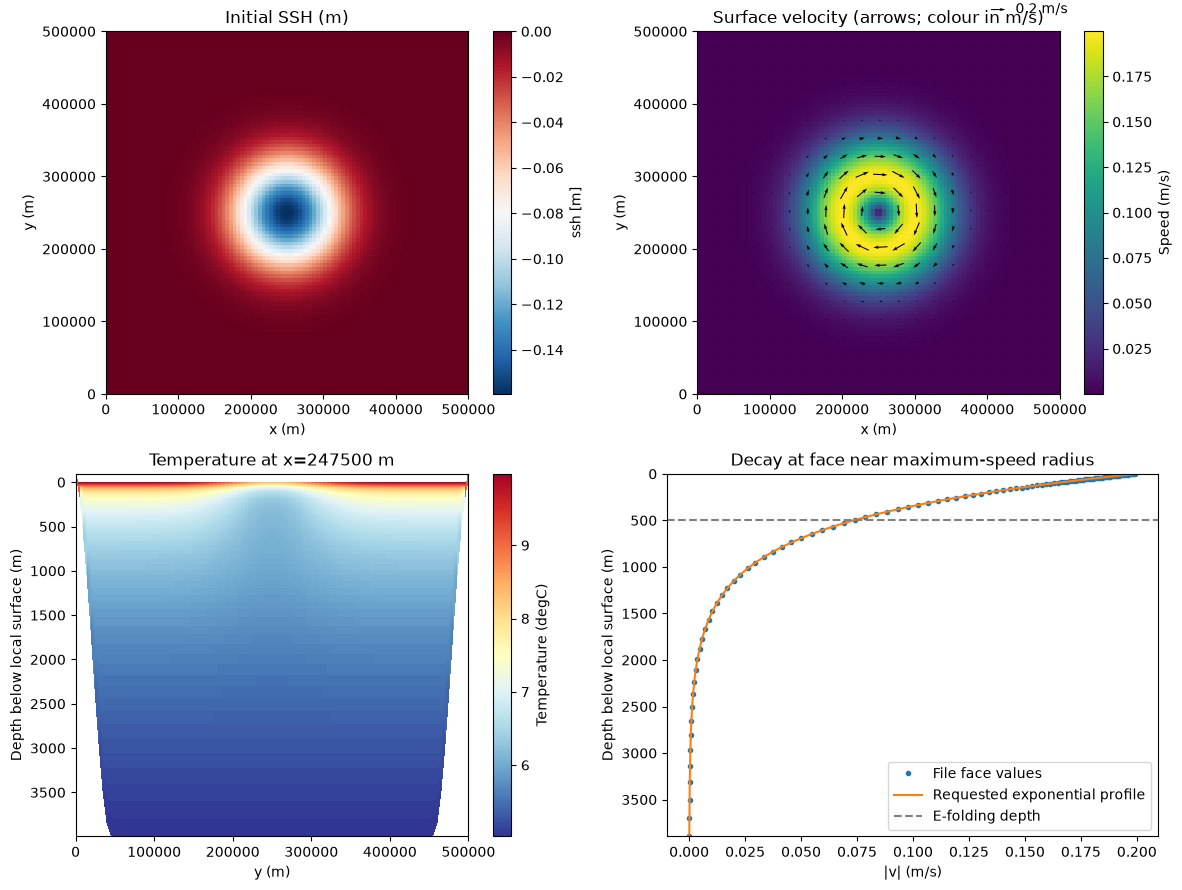

In [3]:
with xr.open_dataset(output_path, decode_times=False) as state:
    fig = plot_state(state)
    plt.show()

## Interpretation and fresh-start handoff

Check the printed stability results **before running**. For the agreed first test, the derivative of velocity jumps at 1,000 m: the cold cyclonic thermal anomaly disappears below it, producing a density inversion. The configured `instability_action: warn` deliberately retains this profile; set it to `error` if generation should stop on instability. No smoothing or extra stratification has been introduced.

The surface speed is checked within 2% sampling tolerance, and peak radius within two horizontal grid spacings. The top-layer speed is slightly lower than the mathematical surface maximum because its midpoint is below the surface. Normal flow at the closed walls, finite wet values, positive wet thicknesses, exact bottom/surface geometry, cyclonic sign, linear decay, zero flow below 1,000 m, hydrostatic column consistency and a centred interior geostrophic residual are checked after reopening the NetCDF.

`MOM_input` reads `eta`, `temp`, `salt`, `u`, `v` from `initial_state.nc` using the source-verified file initialization options. `ssh` is an inspection variable; no separate SSH read is enabled. The existing Payu input-directory setting stages this file into `INPUT/`. Payu changes staged `input_filename` to `n` when there is no prior restart; an existing restart takes precedence over these initial conditions.

**Do not continue an old restart for this test.** When you choose to run it, use `payu run --new-uuid --initial 0` from the experiment root after sourcing `env.sh`. This creates a separate archive and preserves the old runs. This notebook does not submit that command. No compiled-model initialization has been executed as part of file validation.

CLI (from the experiment root):

```bash
source env.sh
python initialisation/generate_initial_state.py --config initialisation/config.yaml
```

The generated NetCDF is ignored by Git; the YAML, generator, notebook and small validation report are reproducible artifacts. Reference grid/vertical files are stored locally in initialisation/reference/. If grid, topography, vertical coordinate, EOS or Coriolis settings change, regenerate and inspect the validation report; stale reference data are rejected.